# Low-rank adapters and weight merging

Express a low-rank update in factored form and merge it into a base matrix.

LoRA represents an update as a product B A, often scaled by alpha divided by rank. During evaluation the factored branch and the merged weight apply the same linear map. This example specifies the factors directly so the comparison is exact.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

## Construct the weights and test their behaviour

Inspect the arrays and the reference output. Each check describes a specific property of the constructed model.

rank 2 factor parameters 36 dense 80 maximum difference 5.33e-15


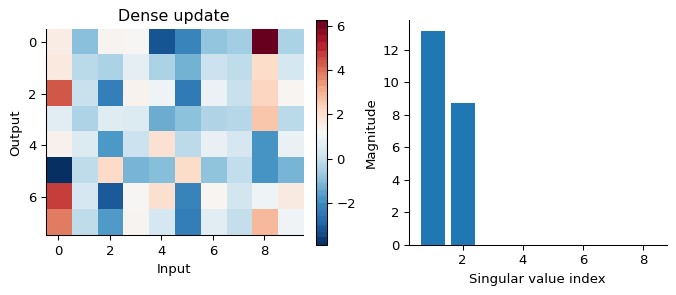

In [2]:
rng = np.random.default_rng(17)
dout, din, r = 8, 10, 2
W = rng.normal(size=(dout, din))
A = rng.normal(size=(r, din))
B = rng.normal(size=(dout, r))
scale = 3 / r
X = rng.normal(size=(40, din))
D = scale * B @ A
branched = X @ W.T + scale * (X @ A.T) @ B.T
merged = X @ (W + D).T
s = np.linalg.svd(D, compute_uv=False)
print(
    "rank",
    np.linalg.matrix_rank(D),
    "factor parameters",
    A.size + B.size,
    "dense",
    D.size,
    "maximum difference",
    f"{np.max(abs(branched-merged)):.2e}",
)
assert np.allclose(branched, merged) and np.linalg.matrix_rank(D) == r
fig, (a, b) = plt.subplots(1, 2, figsize=(7, 3), constrained_layout=True)
im = a.imshow(D, cmap="RdBu_r")
fig.colorbar(im, ax=a)
a.set(title="Dense update", xlabel="Input", ylabel="Output")
b.bar(np.arange(1, len(s) + 1), s)
b.set(xlabel="Singular value index", ylabel="Magnitude")
plt.show()

## Interpreting the result

The parameter saving depends on rank and layer shape. Merger equivalence checks the arithmetic, while learned task quality requires a separate evaluation.

## Exercise

Increase the rank until the factor count exceeds the dense matrix size.

## References

[Hu et al., LoRA (2021)](https://arxiv.org/abs/2106.09685)

[NumPy, singular value decomposition](https://numpy.org/doc/stable/reference/generated/numpy.linalg.svd.html)